# Phase 1 — model benchmark on Vardhan et al.'s 3,021 hulls

## M0: analytic baseline (ITTC-1957 friction × Hoerner form factor × wetted area)

In [3]:
import sys, numpy as np
sys.path.insert(0, '..')
from models.physics import drag_m0
test = np.loadtxt('../reference/UUV-design-optimization/uuv_optim/data/surrogate/test_data.txt')
pred = np.array([drag_m0(*row[:6]) for row in test])
mape = np.mean(np.abs(pred - test[:, 6]) / test[:, 6]) * 100
print(f"M0 mean absolute % error on their 621 test hulls: {mape:.1f}%")

M0 mean absolute % error on their 621 test hulls: 4.7%


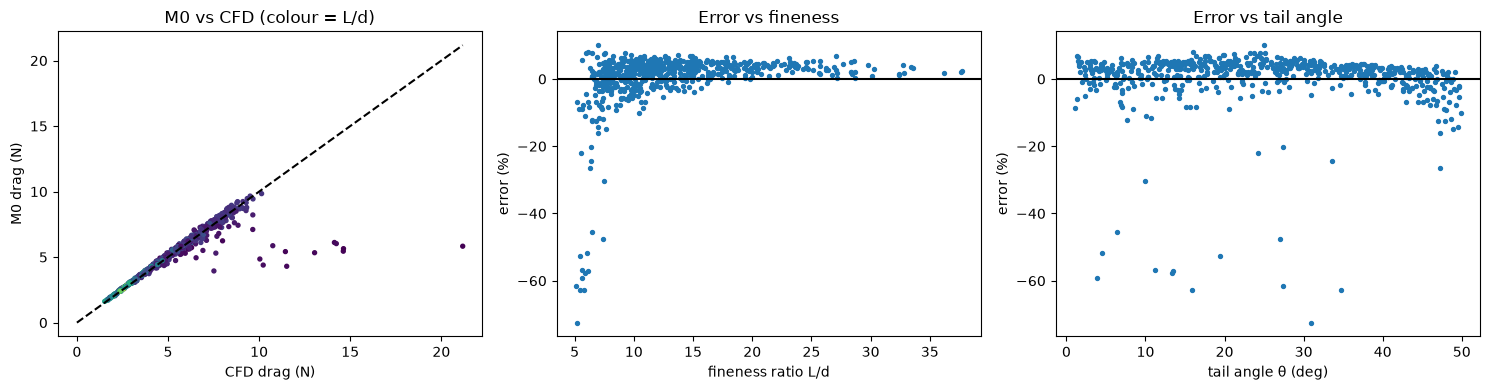

10 worst hulls:  L/d   θ    CFD(N)  M0(N)  error%
               5.2  31.0   21.17   5.83   -72.5
               5.5  34.7   14.62   5.45   -62.7
               5.8  15.9   11.51   4.30   -62.6
               5.1  27.4   14.63   5.65   -61.4
               5.6   3.8   13.04   5.33   -59.1
               5.9  13.4   14.24   6.03   -57.6
               6.2  13.4   10.22   4.39   -57.0
               5.6  11.2   14.13   6.12   -56.7
               5.4  19.5   11.44   5.42   -52.6
               6.1   4.5   10.04   4.85   -51.6

Share of hulls within ±5%: 77%


In [4]:
import matplotlib.pyplot as plt

a, b, c, d, n, th, D = test.T              # unpack the 7 columns
L = a + b + c                               # total length (mm)
fineness = L / d                            # length / diameter: low = fat, blunt hull
err = (pred - D) / D * 100                  # signed % error (negative = M0 under-predicts)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(D, pred, s=8, c=fineness, cmap='viridis'); ax[0].plot([0, D.max()], [0, D.max()], 'k--')
ax[0].set(xlabel='CFD drag (N)', ylabel='M0 drag (N)', title='M0 vs CFD (colour = L/d)')
ax[1].scatter(fineness, err, s=8); ax[1].axhline(0, c='k')
ax[1].set(xlabel='fineness ratio L/d', ylabel='error (%)', title='Error vs fineness')
ax[2].scatter(th, err, s=8); ax[2].axhline(0, c='k')
ax[2].set(xlabel='tail angle θ (deg)', ylabel='error (%)', title='Error vs tail angle')
plt.tight_layout(); plt.show()

worst = np.argsort(-np.abs(err))[:10]
print("10 worst hulls:  L/d   θ    CFD(N)  M0(N)  error%")
for i in worst:
    print(f"            {fineness[i]:6.1f} {th[i]:5.1f} {D[i]:7.2f} {pred[i]:6.2f} {err[i]:7.1f}")
print(f"\nShare of hulls within ±5%: {np.mean(np.abs(err) < 5) * 100:.0f}%")

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler

train = np.loadtxt('../reference/UUV-design-optimization/cad_cfd_pipeline_surrogate_data_generation/surrogate_data/train_2400.txt')
Xtr, ytr = train[:, :6], train[:, 6]
Xte, yte = test[:, :6], test[:, 6]

def mape(p, y): return np.mean(np.abs(p - y) / y) * 100

# M2: gradient-boosted trees
m2 = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=0).fit(Xtr, ytr)
p2 = m2.predict(Xte)

# M3: Gaussian process; scale inputs, fit log(drag) so errors are relative
sx = StandardScaler().fit(Xtr)
kernel = ConstantKernel() * Matern(length_scale=np.ones(6), nu=2.5) + WhiteKernel()
m3 = GaussianProcessRegressor(kernel, normalize_y=True, random_state=0).fit(sx.transform(Xtr), np.log(ytr))
mu, sd = m3.predict(sx.transform(Xte), return_std=True)
p3 = np.exp(mu)
inside = np.mean(np.abs(np.log(yte) - mu) < 2 * sd) * 100

print(f"M0 physics            : {mape(pred, yte):5.2f}%")
print(f"M2 gradient boosting  : {mape(p2, yte):5.2f}%")
print(f"M3 Gaussian process   : {mape(p3, yte):5.2f}%   ({inside:.0f}% of test hulls inside its ±2σ band; ideal ≈ 95%)")
print(f"   paper's network (optimistic): 1.85%")
for name, p in [("M0", pred), ("M2", p2), ("M3", p3)]:
    print(f"   {name} on fat hulls (L/d < 7): {mape(p[fineness < 7], yte[fineness < 7]):5.1f}%")

M0 physics            :  4.68%
M2 gradient boosting  :  3.32%
M3 Gaussian process   :  1.84%   (96% of test hulls inside its ±2σ band; ideal ≈ 95%)
   paper's network (optimistic): 1.85%
   M0 on fat hulls (L/d < 7):  18.5%
   M2 on fat hulls (L/d < 7):  15.7%
   M3 on fat hulls (L/d < 7):  14.2%


In [7]:
import torch, torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
torch.manual_seed(0); rng = np.random.default_rng(0)

class SNet(nn.Module):                      # their architecture, written cleanly
    def __init__(s):
        super().__init__()
        w = [6, 128, 64, 64, 32, 32, 64, 64, 8, 1]
        s.fc = nn.ModuleList(nn.Linear(w[i], w[i + 1]) for i in range(9))
    def forward(s, x):
        x = torch.relu(s.fc[0](x)); x = torch.relu(s.fc[1](x))
        h = s.fc[2](x); x = h + torch.relu(h)              # their skip connection
        for f in s.fc[3:8]: x = torch.relu(f(x))
        return s.fc[8](x)

idx = rng.permutation(len(Xtr)); va, tr = idx[:240], idx[240:]       # 10% validation, test untouched
sxm, sym = MinMaxScaler().fit(Xtr[tr]), MinMaxScaler().fit(ytr[tr, None])
T = lambda a: torch.tensor(a, dtype=torch.float32)
xt, yt = T(sxm.transform(Xtr[tr])), T(sym.transform(ytr[tr, None]))
xv, yv = T(sxm.transform(Xtr[va])), T(sym.transform(ytr[va, None]))

net = SNet(); opt = torch.optim.Adam(net.parameters(), lr=1e-3); best = (1e9, None)
for epoch in range(400):
    for i in torch.randperm(len(xt)).split(32):
        opt.zero_grad(); nn.functional.l1_loss(net(xt[i]), yt[i]).backward(); opt.step()
    with torch.no_grad(): v = nn.functional.l1_loss(net(xv), yv).item()
    if v < best[0]: best = (v, {k: t.clone() for k, t in net.state_dict().items()})
net.load_state_dict(best[1])

with torch.no_grad(): p1 = sym.inverse_transform(net(T(sxm.transform(Xte))).numpy()).ravel()
print(f"M1 their network, clean : {mape(p1, yte):5.2f}%   (paper: 1.85%)")
print(f"   M1 on fat hulls (L/d < 7): {mape(p1[fineness < 7], yte[fineness < 7]):5.1f}%")

M1 their network, clean :  2.38%   (paper: 1.85%)
   M1 on fat hulls (L/d < 7):  17.5%
